Question: whether an error page cost sales

Data: all visits who arrived from Nov1st to Dec 24th (their visits run until Jan31st); first visit buyer included.

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

from ga4case.path import SESSIONS, USERS, FIGURES

In [2]:
con = duckdb.connect()
con.sql(
    f"create or replace view sessions as select * from read_parquet('{SESSIONS.as_posix()}')"
)
con.sql(
    f"create or replace view users as select * from read_parquet('{USERS.as_posix()}')"
);

In [3]:
# New users from Nov 1st to Dec 24th
con.sql("""
    create or replace view visits as
    select s.*,
        row_number() over (partition by s.user_pseudo_id order by s.session_start) as visit_order
    from sessions s
    join (
        select user_pseudo_id
        from users
        where first_session_number = 1
            and first_visit_start < timestamp '2020-12-25'
    ) cohort using (user_pseudo_id)
""")
con.sql("""
    select count(distinct user_pseudo_id) as users,
        count(*) as visits,
        sum(purchased)::int as purchase_visits,
        sum(saw_error_page)::int as error_visits
    from visits
""").df()

,users,visits,purchase_visits,error_visits
0,154160,208232,2952,5573


In [4]:
# Purchase rate from users who saw error page vs no error page
con.sql("""
    select saw_error_page,
        count(*) as visits,
        sum(purchased)::int as purchases,
        round(100 * avg(purchased), 2) as pct_purchase
    from visits
    group by 1
    order by 1
""").df()

,saw_error_page,visits,purchases,pct_purchase
0,0,202659,2951,1.46
1,1,5573,1,0.02


In [5]:
# Check the ratio when users met the error page
con.sql("""
    select
        case when landing_page_title = 'Page Unavailable' then 'the visit starts on the error page'
             else 'the error page comes later in the visit' end as how,
        count(*) as visits,
        round(100.0 * count(*) / sum(count(*)) over (), 1) as pct_of_error_visits,
        median(distinct_pages) as median_pages,
        median(active_seconds) as median_active_seconds
    from visits
    where saw_error_page = 1
    group by 1
    order by visits desc
""").df()

,how,visits,pct_of_error_visits,median_pages,median_active_seconds
0,the visit starts on the error page,3916,70.3,1.0,6.276
1,the error page comes later in the visit,1657,29.7,3.0,29.498


In [6]:
# Generate table for one row per user
con.sql("""
    create or replace view per_user as
    select user_pseudo_id,
        count(*) as n_visits,
        max(case when visit_order = 1 then saw_error_page end) as error_first,
        coalesce(max(case when visit_order > 1 then saw_error_page end), 0) as error_later,
        max(saw_error_page) as error_ever,
        max(case when visit_order = 1 then purchased end) as purchase_first,
        max(case when visit_order = 1 then viewed_product end) as viewed_product_first
    from visits
    group by 1
""");

In [7]:
# Test1: users who came back with no error page in the first visit: bought or not in the first visit
test_1 = con.sql("""
    select
        case when error_later = 1 then 'met an error page in later visits'
            else 'no error page met' end as user_group,
        count(*) as users,
        sum(purchase_first)::int as purchase_first,
        round(100*avg(purchase_first), 2) as pct_purchase_first,
        round(100*avg(viewed_product_first),1) as pct_viewed_product_first
    from per_user
    where n_visits >=2
        and error_first = 0
    group by 1
    order by 1 desc        
    """).df()

test_1

,user_group,users,purchase_first,pct_purchase_first,pct_viewed_product_first
0,no error page met,27025,627,2.32,35.4
1,met an error page in later visits,1023,2,0.20,14.8


In [8]:
# Check the number of distinct pages that buyers viewed
con.sql("""
    select
        count(*) as purchase_visits,
        count(*) filter (where distinct_pages >= 4) as with_4_or_more_pages,
        round(100.0 * count(*) filter (where distinct_pages >= 4) / count(*), 1) as pct_with_4_or_more_pages,
        median(distinct_pages) as median_pages
    from visits
    where purchased = 1
""").df()

,purchase_visits,with_4_or_more_pages,pct_with_4_or_more_pages,median_pages
0,2952,2950,99.9,14.0


In [9]:
# Check whether users purchase normally when no error or error met in another visit
test_2 = con.sql("""
    select
        case when u.error_ever = 1 then 'met an error page in another visit'
             else 'never met an error page' end as user_group,
        count(*) as visits,
        sum(v.purchased)::int as purchases,
        round(100 * avg(v.purchased), 2) as pct_purchase,
        round(100 * avg(v.viewed_product), 1) as pct_viewed_product
    from visits v
    join per_user u using (user_pseudo_id)
    where v.saw_error_page = 0
        and v.distinct_pages >= 4
    group by 1
    order by 1 desc
""").df()

test_2


,user_group,visits,purchases,pct_purchase,pct_viewed_product
0,never met an error page,33586,2943,8.76,75.2
1,met an error page in another visit,564,6,1.06,73.8


In [10]:
# Splitting results on the same visits - purchased before or after the first error visit
con.sql("""
    with first_error as (
        select user_pseudo_id, min(visit_order) as first_error_order
        from visits
        where saw_error_page = 1
        group by 1
    )
    select
        case when f.first_error_order is null then '1: never met an error page'
             when v.visit_order < f.first_error_order then '2: before the first error visit'
             else '3: after the first error visit' end as timing,
        count(*) as visits,
        sum(v.purchased)::int as purchases,
        round(100 * avg(v.purchased), 2) as pct_purchase
    from visits v
    left join first_error f using (user_pseudo_id)
    where v.saw_error_page = 0
        and v.distinct_pages >= 4
    group by 1
    order by 1
""").df()

,timing,visits,purchases,pct_purchase
0,1: never met an error page,33586,2943,8.76
1,2: before the first error visit,298,2,0.67
2,3: after the first error visit,266,4,1.50


In [11]:
# Match purchased rate to estimate the purchase in two tests
pd.DataFrame(
    {
        "group_size": [test_1.loc[1, "users"], test_2.loc[1, "visits"]],
        "purchases_expected_at_the_other_groups_rate": [
            test_1.loc[1, "users"] * test_1.loc[0, "pct_purchase_first"] / 100,
            test_2.loc[1, "visits"] * test_2.loc[0, "pct_purchase"] / 100,
        ],
        "purchases_observed": [
            test_1.loc[1, "purchase_first"],
            test_2.loc[1, "purchases"],
        ],
    },
    index=[
        "Test 1: first visit, before any error",
        "Test 2: error-free visit of 4+ pages",
    ],
).round(1)

,group_size,purchases_expected_at_the_other_groups_rate,purchases_observed
"Test 1: first visit, before any error",1023,23.7,2
Test 2: error-free visit of 4+ pages,564,49.4,6


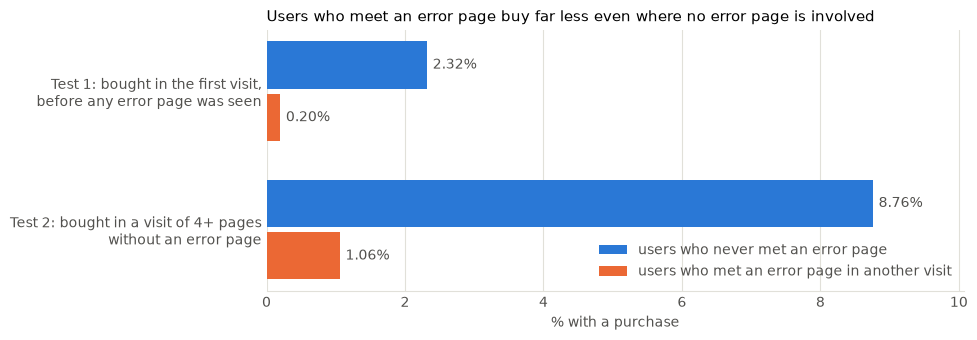

In [12]:
tests = [
    "Test 1: bought in the first visit,\nbefore any error page was seen",
    "Test 2: bought in a visit of 4+ pages\nwithout an error page",
]
never = [test_1.loc[0, "pct_purchase_first"], test_2.loc[0, "pct_purchase"]]
met = [test_1.loc[1, "pct_purchase_first"], test_2.loc[1, "pct_purchase"]]

fig, ax = plt.subplots(figsize=(9, 3.4))
y = range(len(tests))
bars_never = ax.barh(
    [i - 0.19 for i in y],
    never,
    height=0.34,
    color="#2a78d6",
    label="users who never met an error page",
)
bars_met = ax.barh(
    [i + 0.19 for i in y],
    met,
    height=0.34,
    color="#eb6834",
    label="users who met an error page in another visit",
)
ax.bar_label(
    bars_never, labels=[f"{v:.2f}%" for v in never], padding=4, color="#52514e"
)
ax.bar_label(bars_met, labels=[f"{v:.2f}%" for v in met], padding=4, color="#52514e")
ax.set_yticks(list(y), tests)
ax.invert_yaxis()
ax.set_xlim(0, max(never) * 1.15)
ax.set_xlabel("% with a purchase", color="#52514e")
ax.tick_params(colors="#52514e", length=0)
ax.grid(axis="x", color="#e1e0d9")
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#e1e0d9")
ax.legend(frameon=False, loc="lower right", labelcolor="#52514e")
ax.set_title(
    "Users who meet an error page buy far less even where no error page is involved",
    loc="left",
    fontsize=11,
)
fig.savefig(FIGURES / "error_page_tests.png", dpi=500, bbox_inches="tight")
plt.show()

Findings:
1. 1 of 5573 visits met an error had a purchase, while other visits have much higher purchase rate: 1.46% vs 0.02%.
2. 70.3% error visits started on an error page.
3. 99.9% purchase behaviour have 4 or more pages viewed.
4. Test_1 showed that among users who came back with no error page in the first visit: users who met an error in later visit is far lower than who did not met an error regarding to the purchase rate in the first visit (0.2% vs 2.32%).-- It means that this is a group difference not due to the error page, as apparently here error pages in later time has nothing to do with the previous purchase.
5. Test_2 showed that in visits with no less than 4 pages viewed without an error page: the purchase from visitors who met an error page in another visit is far lower than that of visitors who did not met an error (1.06% vs 8.76%). And splitting of the met an error visits, it showed that purchase before or after the error met both showed very lower rate (0.67% and 1.50%), so this gap is not caused by error page.
6. Result showed that error met groups seldom buy but it did not prove that error page cost sales.
7. Limits:
    - fix borken links may not result in more sales
    - limited data: only 2 and 6 purchases in the error met group.
    - extra experiments need to measure whether en error page cost sales.